# Q3: Matplotlib – Air Quality Visualization
**Aim:** To visualize and analyse PM2.5, PM10 and NO2 levels at 50 stations.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

### Load dataset (create it if the file is not given)

In [2]:
try:
    df = pd.read_csv("03_Matplotlib_Air_Quality.csv")
except FileNotFoundError:
    np.random.seed(42)
    pm25 = np.random.normal(60, 20, 50).clip(10)
    df = pd.DataFrame({"Station_ID": [f"ST{i:02d}" for i in range(1, 51)],
                       "PM2_5": pm25.round(1),
                       "PM10": (1.6 * pm25 + np.random.normal(0, 15, 50)).round(1),
                       "NO2": (0.4 * pm25 + np.random.normal(20, 8, 50)).round(1)})
p = ["PM2_5", "PM10", "NO2"]
df.head()

,Station_ID,PM2_5,PM10,NO2
0,ST01,69.9,116.8,36.7
1,ST02,57.2,85.8,39.5
2,ST03,73.0,106.6,46.4
3,ST04,90.5,153.9,49.8
4,ST05,55.3,104.0,40.8


### 1. Descriptive statistics

In [3]:
df[p].describe().round(2)

,PM2_5,PM10,NO2
count,50.00,50.00,50.00
mean,55.49,89.05,41.88
std,18.68,33.92,10.32
min,20.80,16.80,21.40
25%,42.75,61.00,35.62
50%,55.30,86.50,41.35
75%,66.75,114.90,46.55
max,97.00,160.60,71.70


### 2. Histograms and boxplots

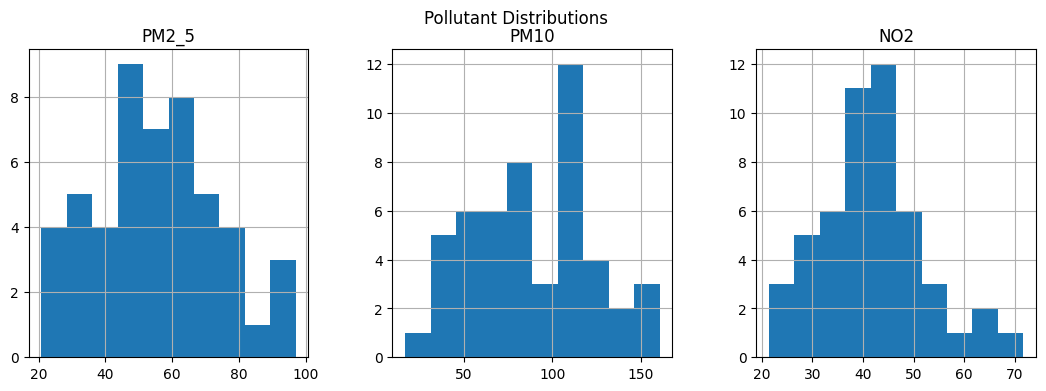

In [4]:
df[p].hist(bins=10, layout=(1, 3), figsize=(13, 4))
plt.suptitle("Pollutant Distributions")
plt.show()

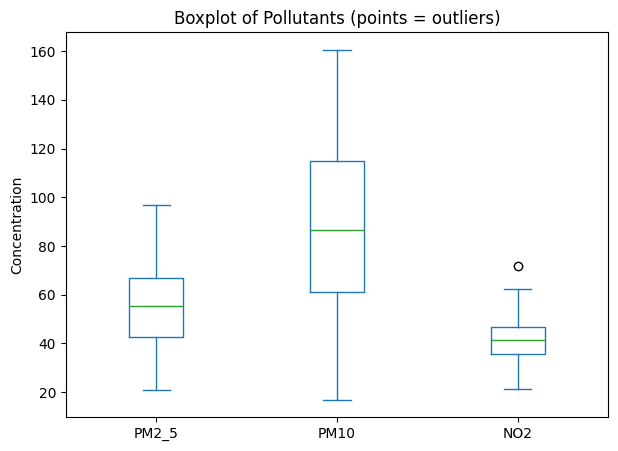

In [5]:
df[p].plot(kind="box", figsize=(7, 5), title="Boxplot of Pollutants (points = outliers)")
plt.ylabel("Concentration")
plt.show()

### 3. Pearson and Spearman correlation

In [6]:
print("Pearson:\n", df[p].corr().round(3))
print("\nSpearman:\n", df[p].corr(method="spearman").round(3))

Pearson:
        PM2_5   PM10    NO2
PM2_5  1.000  0.923  0.625
PM10   0.923  1.000  0.511
NO2    0.625  0.511  1.000

Spearman:
        PM2_5   PM10    NO2
PM2_5   1.00  0.920  0.560
PM10    0.92  1.000  0.465
NO2     0.56  0.465  1.000


### 4. Correlation heatmap

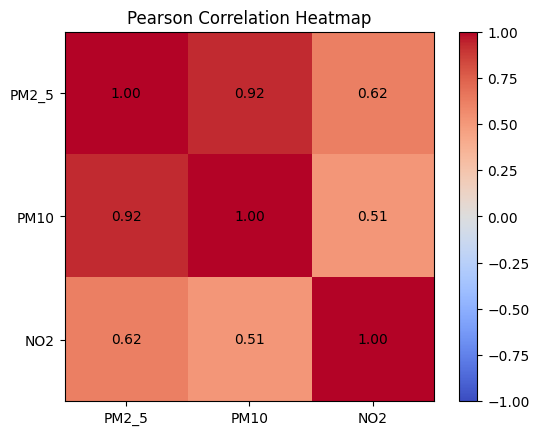

In [7]:
corr = df[p].corr()
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(3), p)
plt.yticks(range(3), p)
for i in range(3):
    for j in range(3):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center")
plt.title("Pearson Correlation Heatmap")
plt.show()

Sign gives direction (+ both rise together, − one falls as the other rises). |r| > 0.7 strong, 0.4–0.7 moderate, < 0.4 weak.

### 5. Scatter plots with fitted regression lines

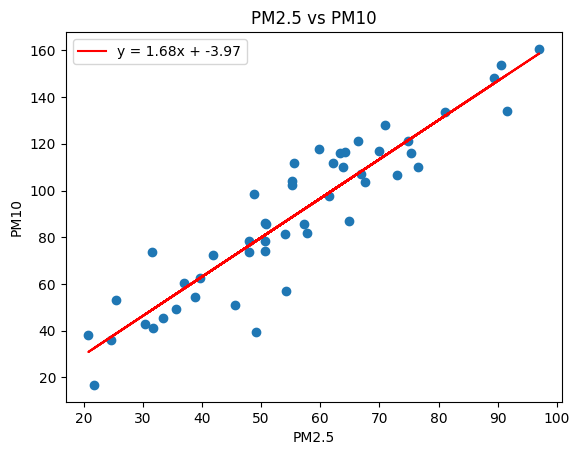

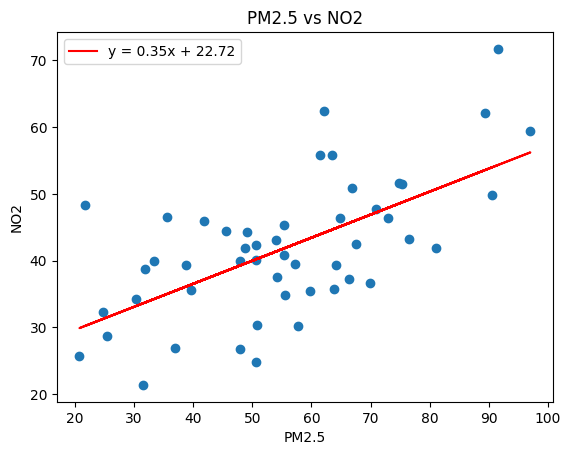

In [8]:
for col in ["PM10", "NO2"]:
    m, c = np.polyfit(df["PM2_5"], df[col], 1)
    plt.scatter(df["PM2_5"], df[col])
    plt.plot(df["PM2_5"], m * df["PM2_5"] + c, color="red", label=f"y = {m:.2f}x + {c:.2f}")
    plt.xlabel("PM2.5")
    plt.ylabel(col)
    plt.title(f"PM2.5 vs {col}")
    plt.legend()
    plt.show()

### 6. Z-scores and |Z| > 2

In [9]:
z = (df[p] - df[p].mean()) / df[p].std()
df[(z.abs() > 2).any(axis=1)].join(z.round(2), rsuffix="_Z")

,Station_ID,PM2_5,PM10,NO2,PM2_5_Z,PM10_Z,NO2_Z
6,ST07,91.6,133.9,71.7,1.93,1.32,2.89
13,ST14,21.7,16.8,48.4,-1.81,-2.13,0.63
31,ST32,97.0,160.6,59.4,2.22,2.11,1.70


### 7. Comparative plot across stations

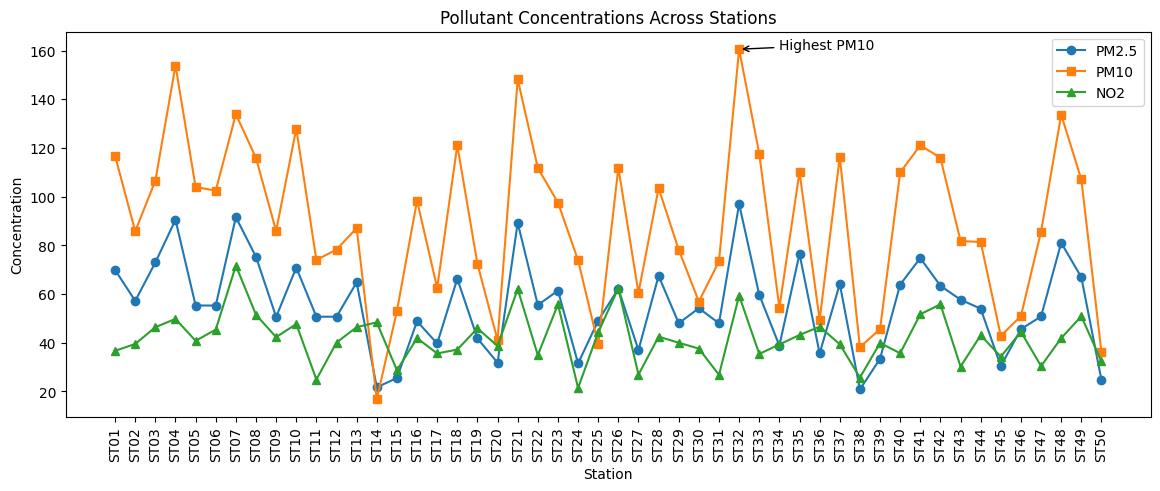

In [10]:
plt.figure(figsize=(14, 5))
plt.plot(df["Station_ID"], df["PM2_5"], marker="o", label="PM2.5")
plt.plot(df["Station_ID"], df["PM10"], marker="s", label="PM10")
plt.plot(df["Station_ID"], df["NO2"], marker="^", label="NO2")
top = df["PM10"].idxmax()
plt.annotate("Highest PM10", (top, df.loc[top, "PM10"]), xytext=(top + 2, df.loc[top, "PM10"]),
             arrowprops=dict(arrowstyle="->"))
plt.xticks(rotation=90)
plt.xlabel("Station")
plt.ylabel("Concentration")
plt.title("Pollutant Concentrations Across Stations")
plt.legend()
plt.show()

### 8. Stations high in multiple pollutants (above 75th percentile in ≥ 2)

In [11]:
high = (df[p] > df[p].quantile(0.75)).sum(axis=1)
df[high >= 2]

,Station_ID,PM2_5,PM10,NO2
0,ST01,69.9,116.8,36.7
3,ST04,90.5,153.9,49.8
6,ST07,91.6,133.9,71.7
7,ST08,75.3,115.9,51.5
9,ST10,70.9,128.0,47.7
20,ST21,89.3,148.3,62.1
31,ST32,97.0,160.6,59.4
40,ST41,74.8,121.1,51.7
41,ST42,63.4,116.0,55.8
47,ST48,81.1,133.7,41.9


**Result:** Air quality data was summarised and visualized using histograms, boxplots, heatmaps, scatter plots and comparative line plots.